In [5]:
from pathlib import Path
import os
from PIL import Image

# Main project folder
PROJECT_DIR = Path(".")

# Your three datasets
FLOOD_DIR = PROJECT_DIR / "Flood Images"
MOUNTAIN_DIR = PROJECT_DIR / "Mountain And Hill Images"
RAIN_SNOW_DIR = PROJECT_DIR / "Rain And Snow Images"

print("Flood folder exists:", FLOOD_DIR.exists())
print("Mountain/Hill folder exists:", MOUNTAIN_DIR.exists())
print("Rain/Snow folder exists:", RAIN_SNOW_DIR.exists())
   

Flood folder exists: True
Mountain/Hill folder exists: True
Rain/Snow folder exists: True


In [10]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def find_images(folder):
    return [
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

flood_images = find_images(FLOOD_DIR)
mountain_images = find_images(MOUNTAIN_DIR)
rain_snow_images = find_images(RAIN_SNOW_DIR)

print("Flood images:", len(flood_images))
print("Mountain/Hill images:", len(mountain_images))
print("Rain/Snow images:", len(rain_snow_images))

Flood images: 882
Mountain/Hill images: 24335
Rain/Snow images: 26472


In [11]:
from collections import Counter

def show_folder_structure(folder, name):
    print(f"\n===== {name} =====")

    subfolders = [
        p for p in folder.rglob("*")
        if p.is_dir()
    ]

    if subfolders:
        for p in subfolders[:30]:
            images = find_images(p)
            if images:
                print(f"{p}  -->  {len(images)} images")
    else:
        print("No subfolders found.")

show_folder_structure(FLOOD_DIR, "FLOOD")
show_folder_structure(MOUNTAIN_DIR, "MOUNTAIN / HILL")
show_folder_structure(RAIN_SNOW_DIR, "RAIN / SNOW")


===== FLOOD =====
Flood Images\Dataset  -->  882 images
Flood Images\Dataset\images  -->  441 images
Flood Images\Dataset\labels  -->  441 images

===== MOUNTAIN / HILL =====
Mountain And Hill Images\seg_pred  -->  7301 images
Mountain And Hill Images\seg_test  -->  3000 images
Mountain And Hill Images\seg_train  -->  14034 images
Mountain And Hill Images\seg_pred\seg_pred  -->  7301 images
Mountain And Hill Images\seg_test\seg_test  -->  3000 images
Mountain And Hill Images\seg_train\seg_train  -->  14034 images
Mountain And Hill Images\seg_train\seg_train\buildings  -->  2191 images
Mountain And Hill Images\seg_train\seg_train\forest  -->  2271 images
Mountain And Hill Images\seg_train\seg_train\glacier  -->  2404 images
Mountain And Hill Images\seg_train\seg_train\mountain  -->  2512 images
Mountain And Hill Images\seg_train\seg_train\sea  -->  2274 images
Mountain And Hill Images\seg_train\seg_train\street  -->  2382 images
Mountain And Hill Images\seg_test\seg_test\buildings  -->

In [12]:
# Show only the important class folders from Mountain dataset

mountain_train = MOUNTAIN_DIR / "seg_train" / "seg_train"
mountain_test = MOUNTAIN_DIR / "seg_test" / "seg_test"

print("Mountain training folder:", mountain_train.exists())
print("Mountain test folder:", mountain_test.exists())

if mountain_train.exists():
    for folder in mountain_train.iterdir():
        if folder.is_dir():
            print(folder.name, "->", len(find_images(folder)), "images")

Mountain training folder: True
Mountain test folder: True
buildings -> 2191 images
forest -> 2271 images
glacier -> 2404 images
mountain -> 2512 images
sea -> 2274 images
street -> 2382 images


In [13]:
# Select only the Mountain class

MOUNTAIN_CLASS_DIR = MOUNTAIN_DIR / "seg_train" / "seg_train" / "mountain"

print("Mountain class exists:", MOUNTAIN_CLASS_DIR.exists())

if MOUNTAIN_CLASS_DIR.exists():
    mountain_class_images = find_images(MOUNTAIN_CLASS_DIR)
    print("Mountain class images:", len(mountain_class_images))

Mountain class exists: True
Mountain class images: 2512


In [17]:
# ============================================
# PREPARE CLEAN DATASET PATHS
# ============================================

from pathlib import Path

# Main folders
FLOOD_IMAGE_DIR = FLOOD_DIR / "Dataset" / "images"
MOUNTAIN_CLASS_DIR = MOUNTAIN_DIR / "seg_train" / "seg_train" / "mountain"

print("===== DATASET CHECK =====")

print("Flood images folder exists:", FLOOD_IMAGE_DIR.exists())
print("Mountain images folder exists:", MOUNTAIN_CLASS_DIR.exists())

# Count images
flood_clean_images = find_images(FLOOD_IMAGE_DIR)
mountain_clean_images = find_images(MOUNTAIN_CLASS_DIR)

print("\nFlood/Water images:", len(flood_clean_images))
print("Mountain/Hill images:", len(mountain_clean_images))

===== DATASET CHECK =====
Flood images folder exists: True
Mountain images folder exists: True

Flood/Water images: 441
Mountain/Hill images: 2512


In [18]:
# ============================================
# INSPECT RAIN / SNOW DATASET
# ============================================

print("===== RAIN / SNOW DATASET =====")

rain_snow_folders = [
    p for p in RAIN_SNOW_DIR.rglob("*")
    if p.is_dir()
]

print("Number of folders:", len(rain_snow_folders))
print("\nFirst 25 folders containing images:")

shown = 0

for folder in rain_snow_folders:
    images = find_images(folder)

    if images:
        print(f"{folder} -> {len(images)} images")
        shown += 1

    if shown >= 25:
        break

===== RAIN / SNOW DATASET =====
Number of folders: 235

First 25 folders containing images:
Rain And Snow Images\aaurainsnow -> 13236 images
Rain And Snow Images\Egensevej -> 3005 images
Rain And Snow Images\Hadsundvej -> 1204 images
Rain And Snow Images\Hasserisvej -> 1806 images
Rain And Snow Images\Hjorringvej -> 2411 images
Rain And Snow Images\Hobrovej -> 602 images
Rain And Snow Images\Ostre -> 2408 images
Rain And Snow Images\Ringvej -> 1800 images
Rain And Snow Images\aaurainsnow\Egensevej -> 3005 images
Rain And Snow Images\aaurainsnow\Hadsundvej -> 1204 images
Rain And Snow Images\aaurainsnow\Hasserisvej -> 1806 images
Rain And Snow Images\aaurainsnow\Hjorringvej -> 2411 images
Rain And Snow Images\aaurainsnow\Hobrovej -> 602 images
Rain And Snow Images\aaurainsnow\Ostre -> 2408 images
Rain And Snow Images\aaurainsnow\Ringvej -> 1800 images
Rain And Snow Images\Egensevej\Egensevej-1 -> 600 images
Rain And Snow Images\Egensevej\Egensevej-2 -> 600 images
Rain And Snow Images\Eg

In [7]:
PROTOTYPE_DIR = Path('./prototype_images')
if PROTOTYPE_DIR.exists():
    classes = sorted([p.name for p in PROTOTYPE_DIR.iterdir() if p.is_dir()])
    print('Prototype classes:', len(classes))
    print(classes)
    for c in classes:
        n = len(list((PROTOTYPE_DIR/c).glob('*')))
        print(f'{c}: {n} files')
else:
    print('Create prototype_images/ with one subfolder per verified class when your final 18 classes are selected.')


Create prototype_images/ with one subfolder per verified class when your final 18 classes are selected.


In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = (160,160)
BATCH_SIZE = 8
SEED = 42

if PROTOTYPE_DIR.exists() and any(p.is_dir() for p in PROTOTYPE_DIR.iterdir()):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        PROTOTYPE_DIR, validation_split=0.2, subset='training', seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        PROTOTYPE_DIR, validation_split=0.2, subset='validation', seed=SEED,
        image_size=IMG_SIZE, batch_size=BATCH_SIZE
    )
    class_names = train_ds.class_names
    print('Classes used:', class_names)

    AUTOTUNE = tf.data.AUTOTUNE
    train_ds = train_ds.prefetch(AUTOTUNE)
    val_ds = val_ds.prefetch(AUTOTUNE)

    base = tf.keras.applications.MobileNetV2(input_shape=IMG_SIZE+(3,), include_top=False, weights='imagenet')
    base.trainable = False
    model = models.Sequential([
        layers.Rescaling(1./127.5, offset=-1),
        base,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.2),
        layers.Dense(len(class_names), activation='softmax')
    ])
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    history = model.fit(train_ds, validation_data=val_ds, epochs=5)
    model.save('terrain_classifier.keras')
    with open('class_names.txt','w') as f: f.write('\n'.join(class_names))
    print('Saved terrain_classifier.keras and class_names.txt')
else:
    print('Training skipped: add verified class folders to prototype_images first.')


Training skipped: add verified class folders to prototype_images first.


In [5]:
DRIVE_MODE_MAP = {
    'Highway': {'mode':'ECO/HIGHWAY', 'speed_kmh':80, 'regen':'Medium'},
    'Hill': {'mode':'HILL', 'speed_kmh':35, 'regen':'High'},
    'Mud': {'mode':'MUD', 'speed_kmh':20, 'regen':'Low'},
    'Rock': {'mode':'ROCK', 'speed_kmh':15, 'regen':'Low'},
    'Sand': {'mode':'SAND', 'speed_kmh':25, 'regen':'Low'},
    'Water': {'mode':'WET/WATER', 'speed_kmh':15, 'regen':'Low'},
    'Rain': {'mode':'RAIN', 'speed_kmh':40, 'regen':'Medium'},
}
print(pd.DataFrame(DRIVE_MODE_MAP).T)


                mode speed_kmh   regen
Highway  ECO/HIGHWAY        80  Medium
Hill            HILL        35    High
Mud              MUD        20     Low
Rock            ROCK        15     Low
Sand            SAND        25     Low
Water      WET/WATER        15     Low
Rain            RAIN        40  Medium


In [19]:
# ============================================
# CREATE CLEAN 3-CLASS DATASET
# ============================================

import random
import shutil
from pathlib import Path

random.seed(42)

CLEAN_DATASET_DIR = PROJECT_DIR / "clean_dataset"

classes = {
    "Mountain_Hill": mountain_clean_images,
    "Flood_Water": flood_clean_images,
}

# Rain/Snow dataset:
# We use its RGB camera images as one Bad_Weather class.
rain_snow_images = [
    p for p in RAIN_SNOW_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    and "cam1-" in p.name
]

classes["Bad_Weather"] = rain_snow_images

# Number of images per class
IMAGES_PER_CLASS = 800

# Create folders
for class_name in classes:
    (CLEAN_DATASET_DIR / class_name).mkdir(
        parents=True,
        exist_ok=True
    )

print("===== CLEAN DATASET =====")

for class_name, images in classes.items():

    print(f"\n{class_name}")
    print("Available:", len(images))

    # Shuffle
    selected_images = images.copy()
    random.shuffle(selected_images)

    # Take maximum 800
    selected_images = selected_images[:IMAGES_PER_CLASS]

    destination = CLEAN_DATASET_DIR / class_name

    copied = 0

    for image_path in selected_images:
        target = destination / image_path.name

        # Avoid duplicate filename problems
        if target.exists():
            target = destination / f"{copied}_{image_path.name}"

        shutil.copy2(image_path, target)
        copied += 1

    print("Copied:", copied)

print("\n✅ Clean dataset created!")
print("Location:", CLEAN_DATASET_DIR.resolve())

===== CLEAN DATASET =====

Mountain_Hill
Available: 2512
Copied: 800

Flood_Water
Available: 441
Copied: 441

Bad_Weather
Available: 17584
Copied: 800

✅ Clean dataset created!
Location: M:\AI Auto Drive App\clean_dataset


In [21]:
# ============================================
# VERIFY CLEAN DATASET
# ============================================

from collections import Counter

print("===== CLEAN DATASET CHECK =====")

for class_name in ["Mountain_Hill", "Flood_Water", "Bad_Weather"]:
    folder = CLEAN_DATASET_DIR / class_name
    images = find_images(folder)

    print(f"{class_name}: {len(images)} images")

===== CLEAN DATASET CHECK =====
Mountain_Hill: 800 images
Flood_Water: 441 images
Bad_Weather: 800 images


In [22]:
# ============================================
# FINAL DATASET CHECK + TENSORFLOW CHECK
# ============================================

import tensorflow as tf

print("TensorFlow version:", tf.__version__)

print("\n===== FINAL CLASS COUNTS =====")

for class_name in ["Mountain_Hill", "Flood_Water", "Bad_Weather"]:
    folder = CLEAN_DATASET_DIR / class_name
    images = find_images(folder)
    print(f"{class_name}: {len(images)} images")

print("\nTensorFlow is ready! ✅")

TensorFlow version: 2.20.0

===== FINAL CLASS COUNTS =====
Mountain_Hill: 800 images
Flood_Water: 441 images
Bad_Weather: 800 images

TensorFlow is ready! ✅


In [23]:
# ============================================
# LOAD DATASET
# ============================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    CLEAN_DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    CLEAN_DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

class_names = train_ds.class_names

print("\nClasses:", class_names)
print("Number of classes:", len(class_names))

Found 2041 files belonging to 3 classes.
Using 1633 files for training.
Found 2041 files belonging to 3 classes.
Using 408 files for validation.

Classes: ['Bad_Weather', 'Flood_Water', 'Mountain_Hill']
Number of classes: 3


In [24]:
# ============================================
# BUILD AI TERRAIN / WEATHER CLASSIFIER
# ============================================

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

# Pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build our classifier
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Data augmentation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),

    # MobileNetV2 feature extractor
    base_model,

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [25]:
# ============================================
# TRAIN AI TERRAIN / WEATHER CLASSIFIER
# ============================================

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Stop training if validation performance stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Save the best model during training
checkpoint = ModelCheckpoint(
    "best_auto_drive_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

# Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

print("\n✅ TRAINING COMPLETE!")
print("Best model saved as: best_auto_drive_model.keras")

Epoch 1/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 32s 528ms/step - accuracy: 0.8291 - loss: 0.4007 - val_accuracy: 0.8529 - val_loss: 0.3197
Epoch 2/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 28s 532ms/step - accuracy: 0.9094 - loss: 0.2242 - val_accuracy: 0.9142 - val_loss: 0.2377
Epoch 3/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 28s 537ms/step - accuracy: 0.9284 - loss: 0.1799 - val_accuracy: 0.9363 - val_loss: 0.1688
Epoch 4/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 37s 464ms/step - accuracy: 0.9241 - loss: 0.1776 - val_accuracy: 0.9338 - val_loss: 0.1821
Epoch 5/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 28s 531ms/step - accuracy: 0.9443 - loss: 0.1441 - val_accuracy: 0.9436 - val_loss: 0.1546
Epoch 6/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 29s 559ms/step - accuracy: 0.9394 - loss: 0.1594 - val_accuracy: 0.9240 - val_loss: 0.2134
Epoch 7/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 30s 576ms/step - accuracy: 0.9565 - loss: 0.1124 - val_accuracy: 0.9412 - val_loss: 0.1661
Epoch 8/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 30s 583ms/step - accuracy: 0.9559 - loss: 0.1192 - val_accu

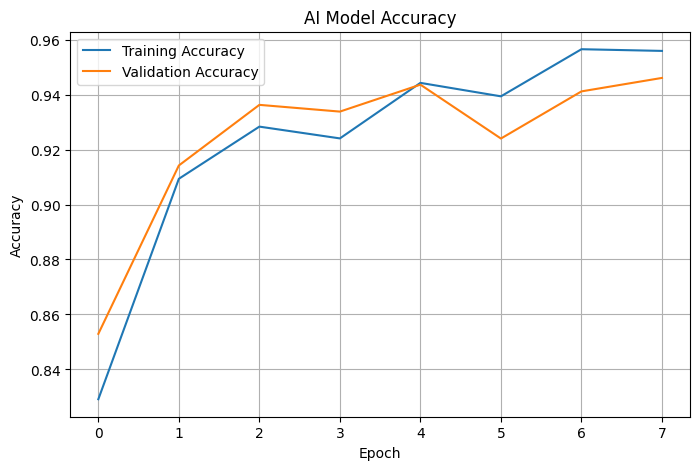

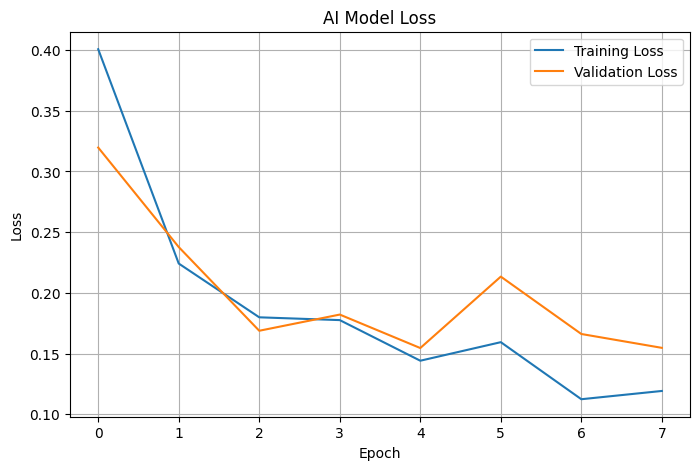

In [26]:
# ============================================
# TRAINING PERFORMANCE GRAPHS
# ============================================

import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("AI Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()


# Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("AI Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

In [27]:
# ============================================
# MODEL EVALUATION
# ============================================

val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)

print("\n==============================")
print("FINAL MODEL EVALUATION")
print("==============================")

print(f"Validation Loss     : {val_loss:.4f}")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 323ms/step - accuracy: 0.9436 - loss: 0.1546

FINAL MODEL EVALUATION
Validation Loss     : 0.1546
Validation Accuracy : 94.36%


13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 321ms/step - accuracy: 0.9436 - loss: 0.1546

FINAL MODEL EVALUATION
Validation Loss     : 0.1546
Validation Accuracy : 94.36%


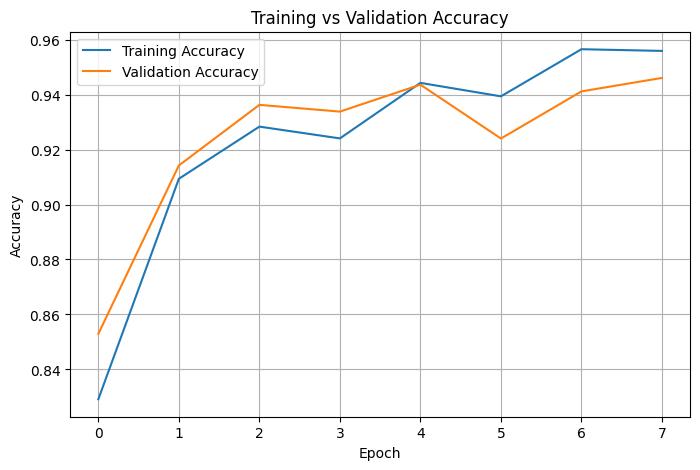

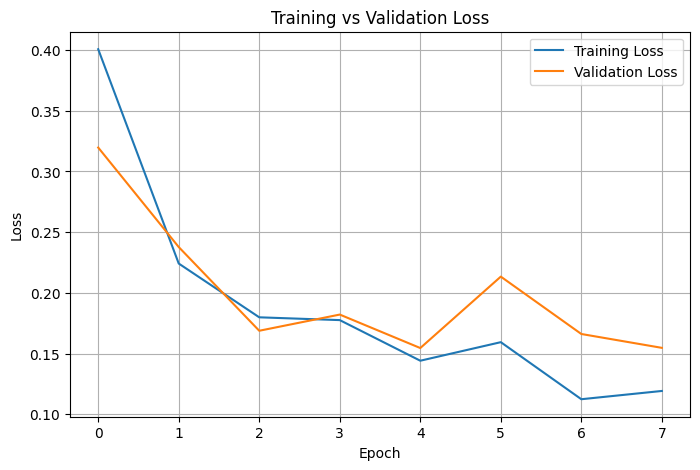

In [28]:
# ============================================
# FINAL MODEL PERFORMANCE
# ============================================

import matplotlib.pyplot as plt

# Evaluate
val_loss, val_accuracy = model.evaluate(val_ds, verbose=1)

print("\n==============================")
print("FINAL MODEL EVALUATION")
print("==============================")
print(f"Validation Loss     : {val_loss:.4f}")
print(f"Validation Accuracy : {val_accuracy * 100:.2f}%")

# Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
# ============================================
# SAVE FINAL AI MODEL
# ============================================

from pathlib import Path

MODEL_DIR = PROJECT_DIR / "model"
MODEL_DIR.mkdir(exist_ok=True)

FINAL_MODEL_PATH = MODEL_DIR / "auto_drive_terrain_model.keras"

model.save(FINAL_MODEL_PATH)

print("================================")
print("MODEL SAVED SUCCESSFULLY! ✅")
print("================================")
print("Model path:")
print(FINAL_MODEL_PATH.resolve())

print("\nClasses:")
for i, name in enumerate(class_names):
    print(i, "->", name)

MODEL SAVED SUCCESSFULLY! ✅
Model path:
M:\AI Auto Drive App\model\auto_drive_terrain_model.keras

Classes:
0 -> Bad_Weather
1 -> Flood_Water
2 -> Mountain_Hill
